In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

In [2]:
path = "../data/processed/Bank_Churn_clean.csv"
df = pd.read_csv(path)
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
df['IsActiveMember'] = df['IsActiveMember'].astype('category')
df['HasCrCard'] = df['HasCrCard'].astype('category')

### Varaible cible

<Axes: title={'center': 'Distribution of Exited (Churn)'}, xlabel='Exited'>

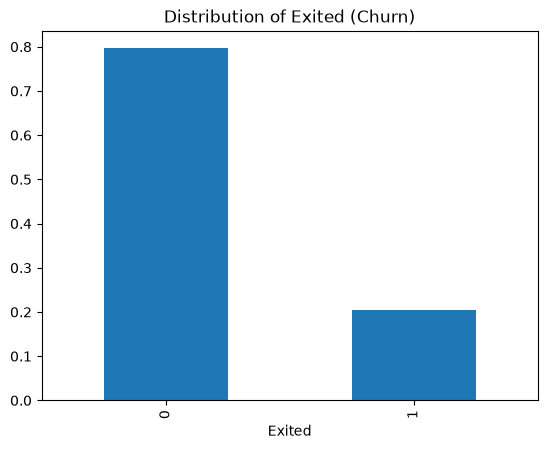

In [23]:
df['Exited'].value_counts(normalize=True).plot(kind='bar', title='Distribution of Exited (Churn)')

### Numeric 

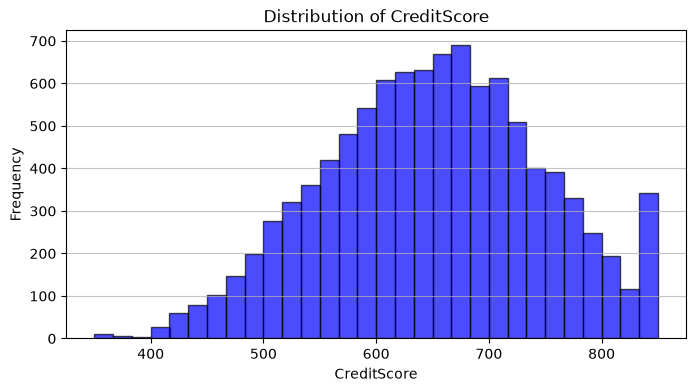

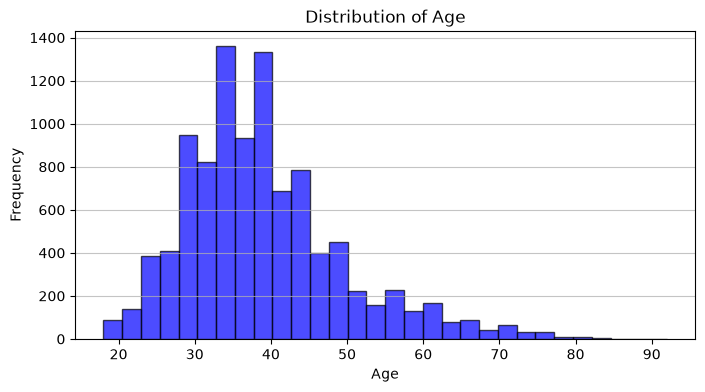

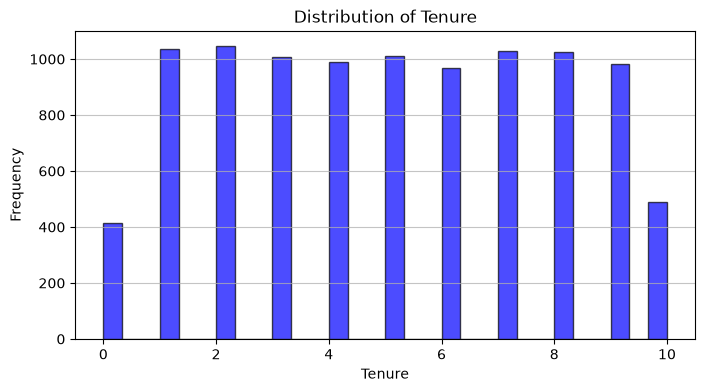

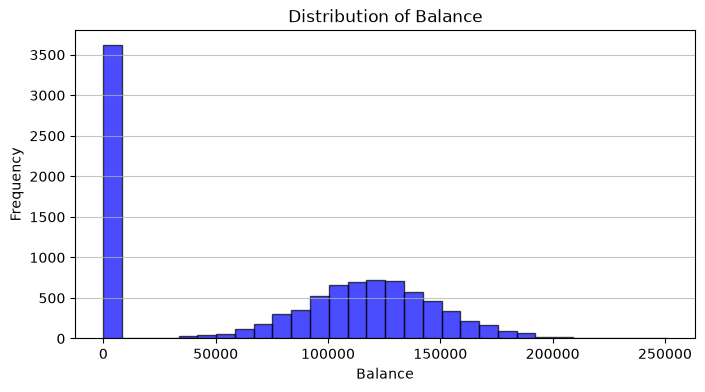

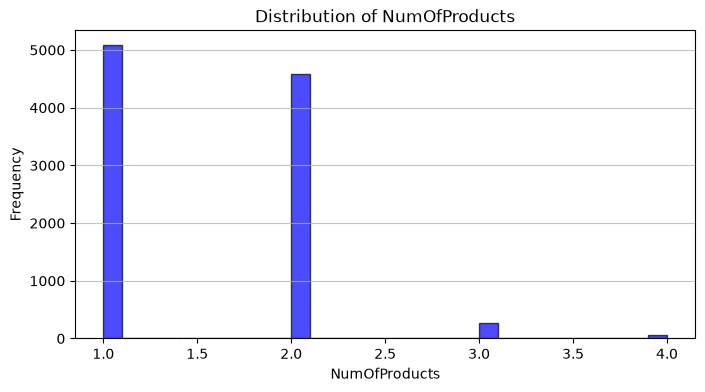

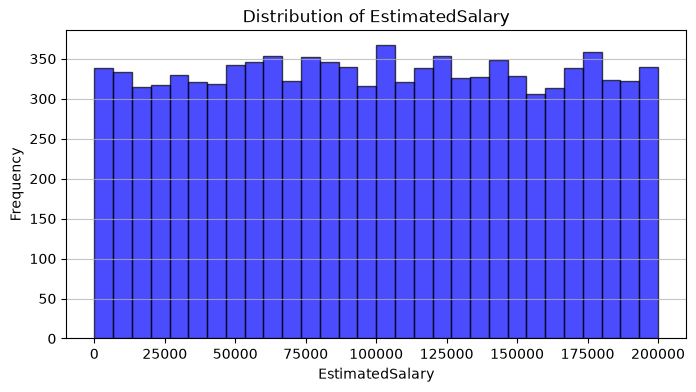

In [24]:
numeric_columns = df.select_dtypes(include=[np.number]).drop(columns=['Exited'])

for column in numeric_columns:
    plt.figure(figsize=(8, 4))
    plt.hist(df[column], bins=30, alpha=0.7, color='blue', edgecolor='black')
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.grid(axis='y', alpha=0.75)
    plt.show()


### Categoric

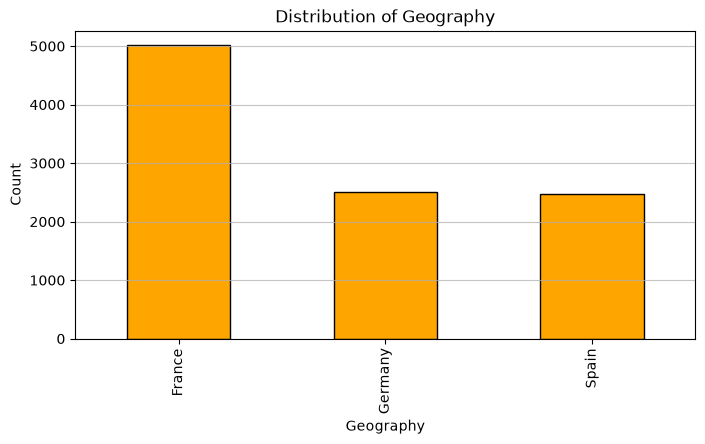

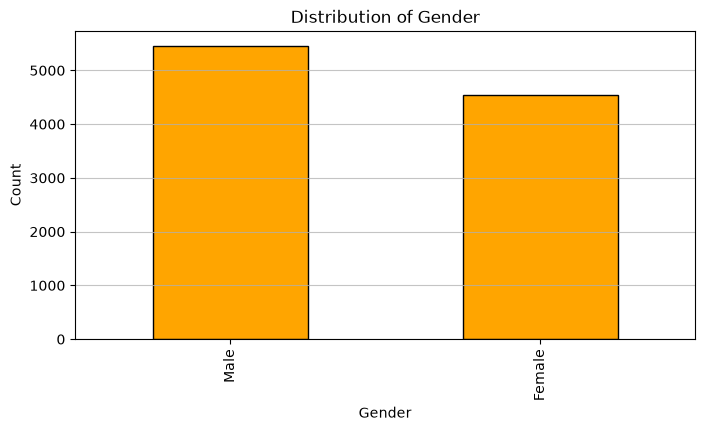

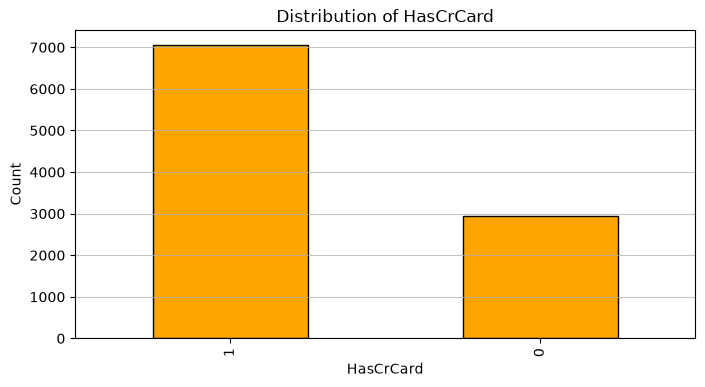

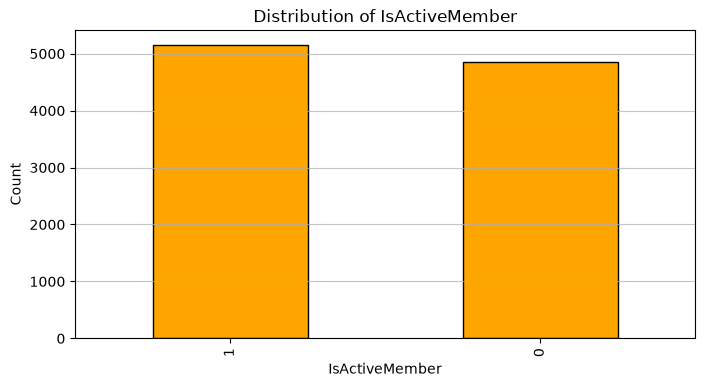

In [13]:
categorical_columns = df.select_dtypes(include=['category', 'str']).columns.tolist()
for column in categorical_columns:
    plt.figure(figsize=(8, 4))
    df[column].value_counts().plot(kind='bar', color='orange', edgecolor='black')
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Count')
    plt.grid(axis='y', alpha=0.75)
    plt.show()

### Correlation entre variable numerique

<Axes: >

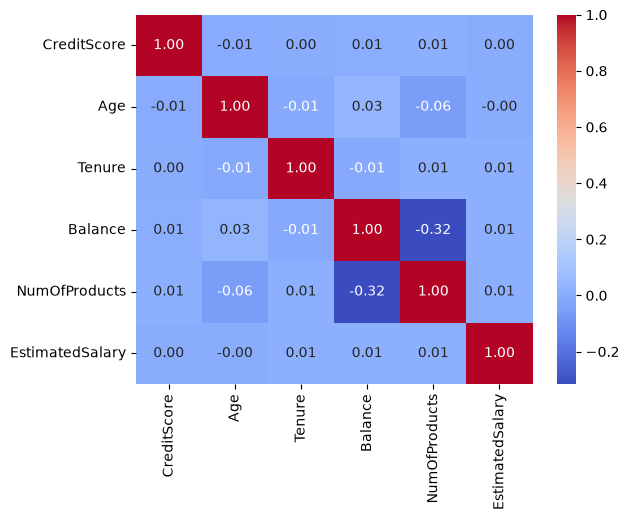

In [28]:
corr = numeric_columns.corr(method='spearman')
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")

In [29]:
# Afficher les paires de variables avec les corrélations absolues les plus fortes
corr_abs = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))

top_corr = (
    corr_abs
    .stack()
    .sort_values(ascending=False)
    .reset_index()
)

top_corr.columns = ['Variable_1', 'Variable_2', 'Correlation_abs']
top_corr.head(10)

,Variable_1,Variable_2,Correlation_abs
0,Balance,NumOfProducts,0.316627
1,Age,NumOfProducts,0.058566
2,Age,Balance,0.033304
3,Tenure,NumOfProducts,0.012908
4,NumOfProducts,EstimatedSalary,0.012570
5,CreditScore,NumOfProducts,0.012568
6,Balance,EstimatedSalary,0.011778
7,Age,Tenure,0.010405
8,Tenure,Balance,0.009513
9,CreditScore,Age,0.007974


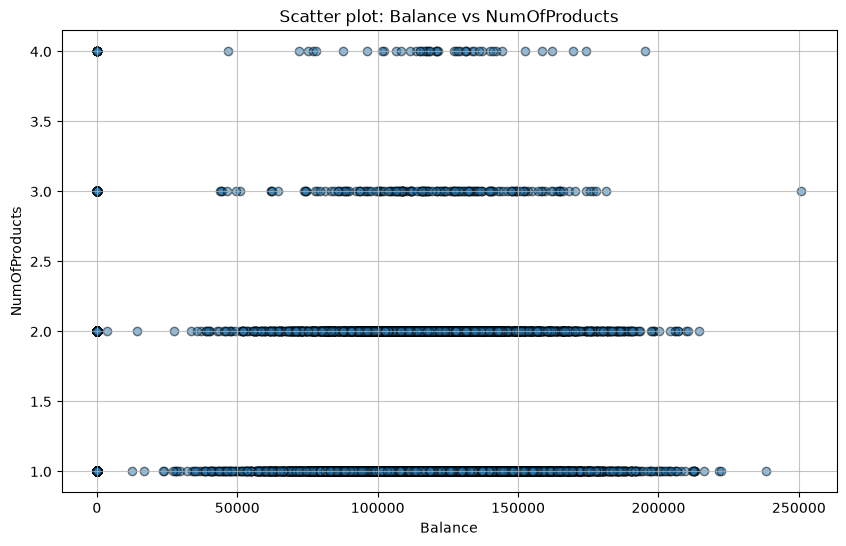

In [30]:
plt.figure(figsize=(10, 6))
plt.scatter(df['Balance'], df['NumOfProducts'], alpha=0.5, edgecolors='k')
plt.xlabel('Balance')
plt.ylabel('NumOfProducts')
plt.title('Scatter plot: Balance vs NumOfProducts')
plt.grid(alpha=0.75)
plt.show()

### Correlation avec la variable cible

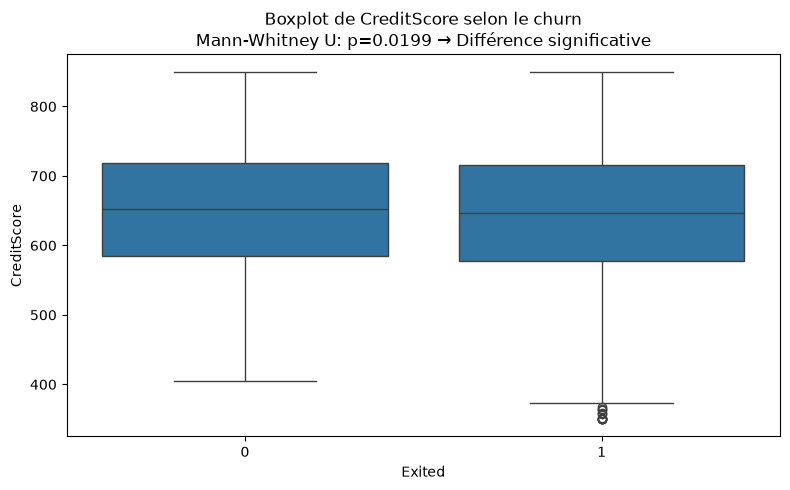

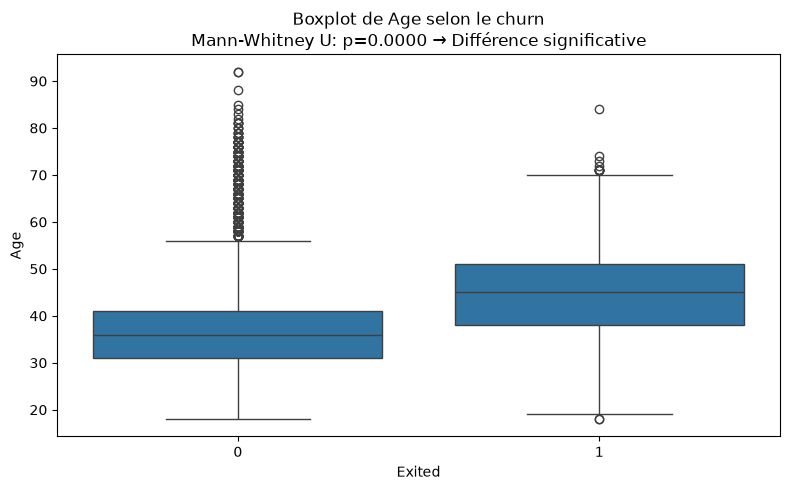

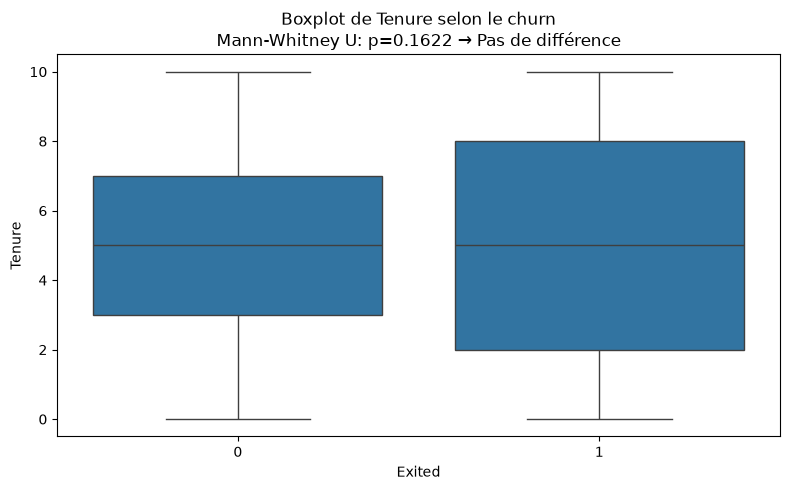

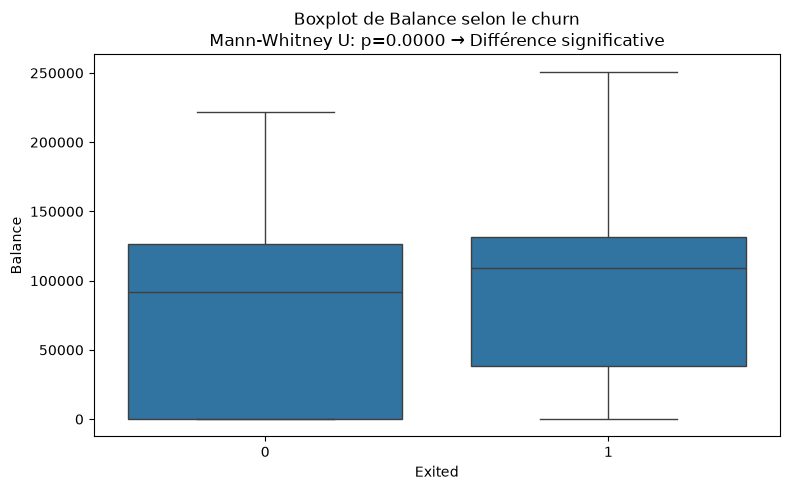

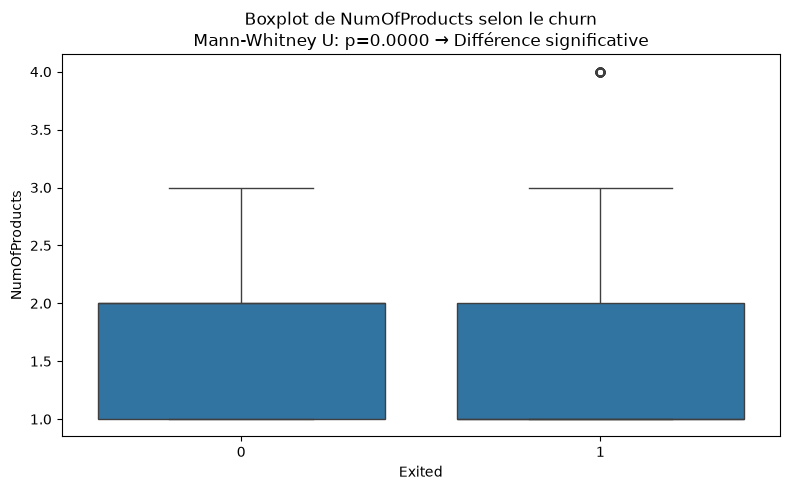

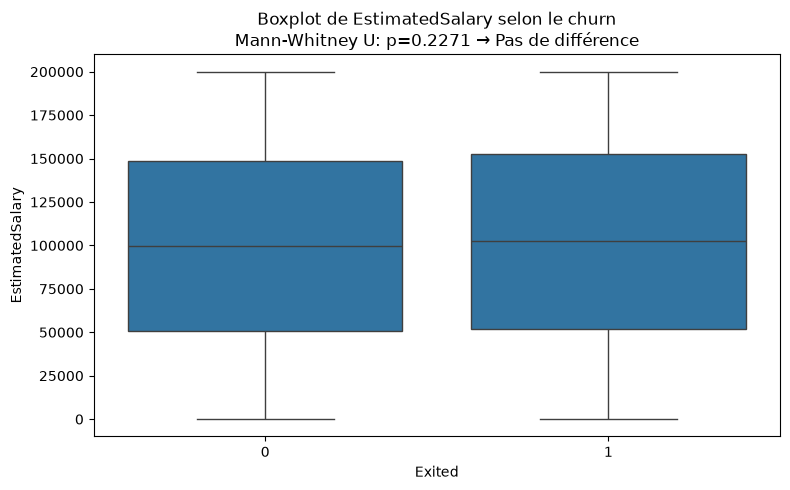

In [32]:
alpha = 0.05  # Niveau de signification

for var in numeric_columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x='Exited', y=var)
    
    # Vérification des groupes
    groupes = df['Exited'].unique()
    if len(groupes) == 2:
        g1 = df[df['Exited'] == groupes[0]][var].dropna()
        g2 = df[df['Exited'] == groupes[1]][var].dropna()
        
        # Test Mann-Whitney
        stat, p_value = mannwhitneyu(g1, g2, alternative='two-sided')
        
        # Interprétation
        if p_value < alpha:
            interpretation = "Différence significative"
        else:
            interpretation = "Pas de différence"
        
        # Titre avec résultats
        plt.title(f'Boxplot de {var} selon le churn\n'
                  f'Mann-Whitney U: p={p_value:.4f} → {interpretation}')
    else:
        plt.title(f'Boxplot de {var} selon le risque\n(Mann-Whitney: besoin de 2 groupes)')
    
    plt.xlabel('Exited')
    plt.ylabel(var)
    plt.tight_layout()
    plt.show()

### Quali-Quali

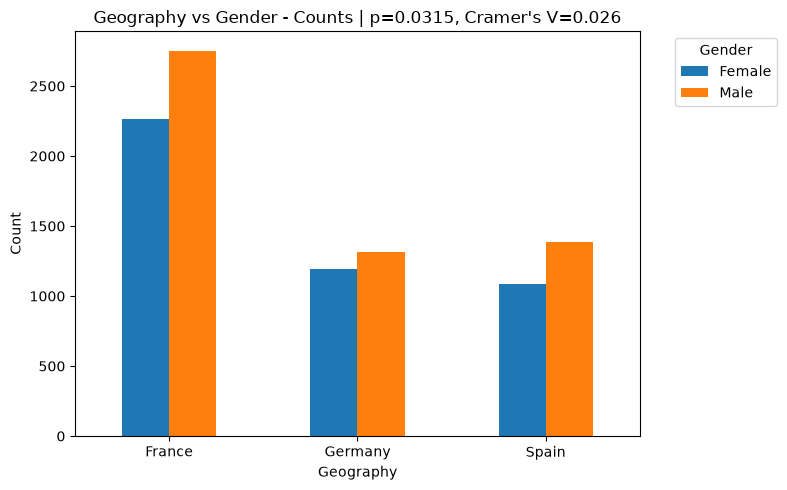

------------------------------------------------------------


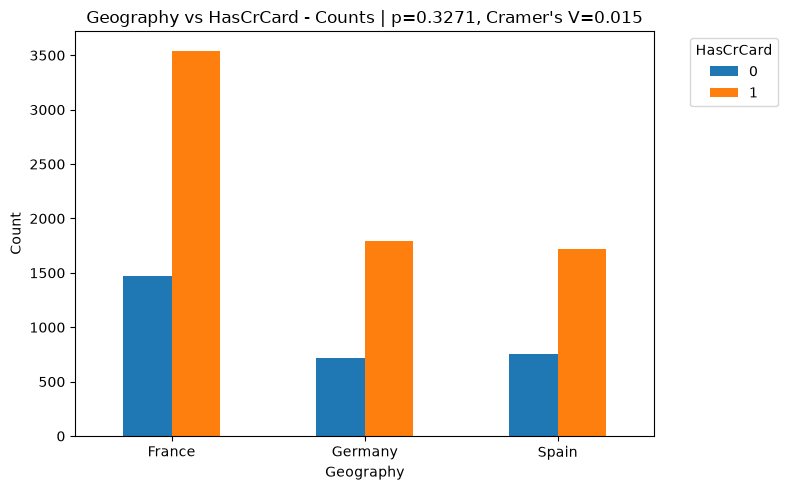

------------------------------------------------------------


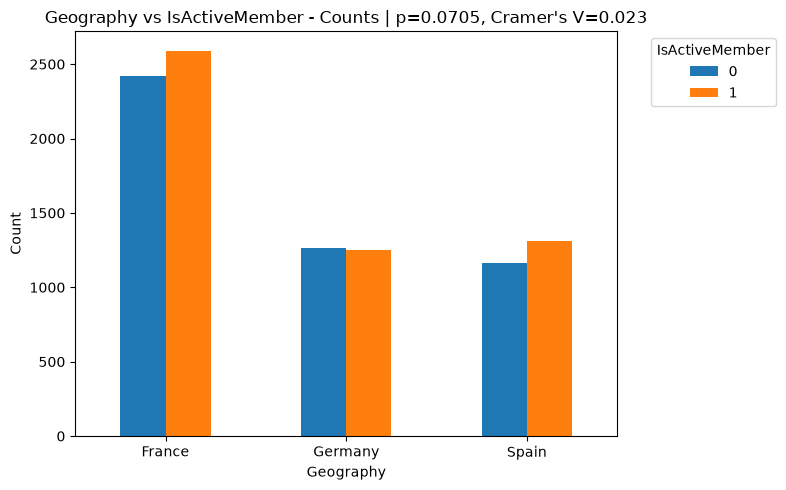

------------------------------------------------------------


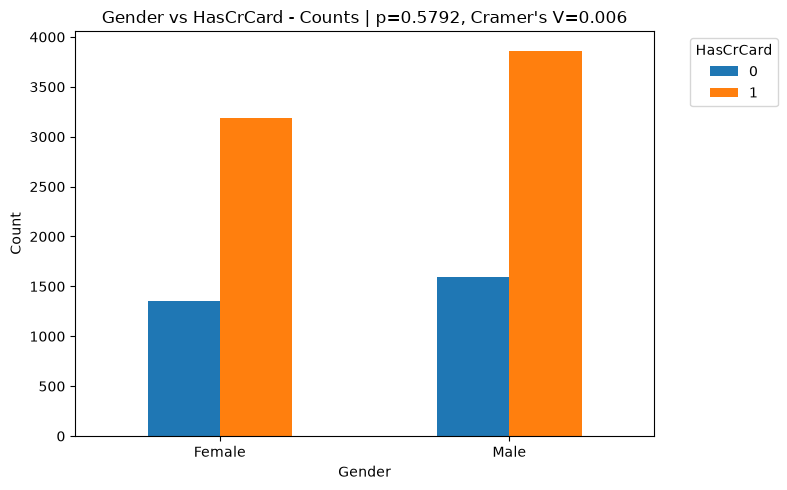

------------------------------------------------------------


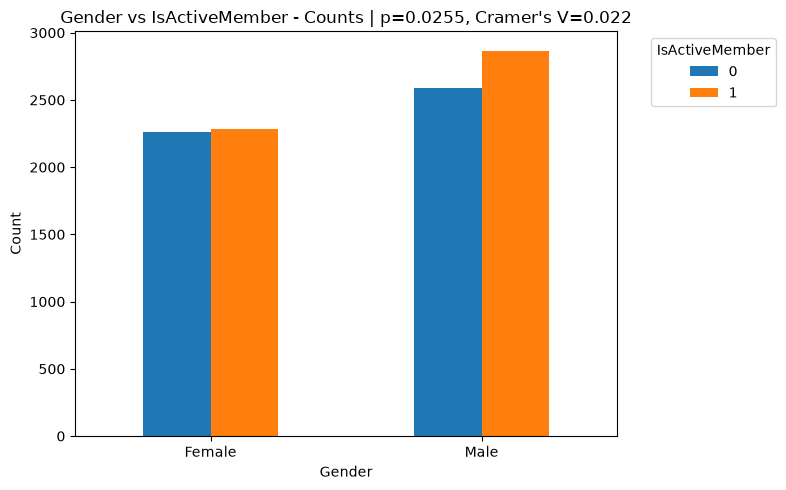

------------------------------------------------------------


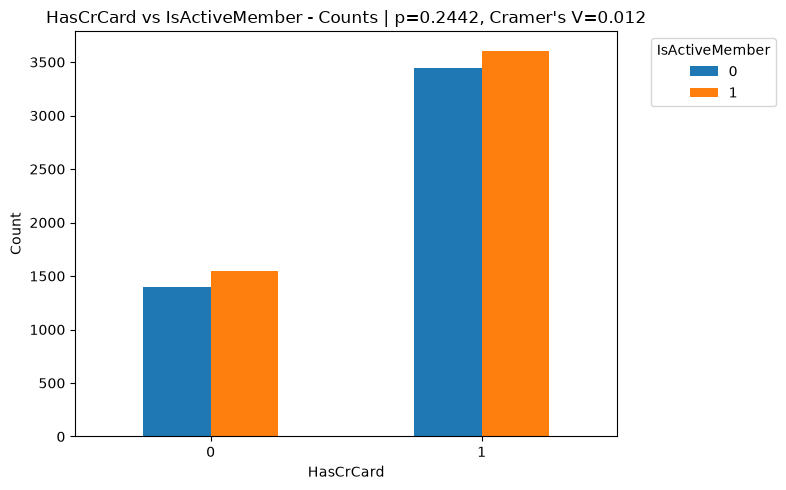

------------------------------------------------------------


In [39]:
from scipy.stats import chi2_contingency

def cramers_v(confusion):
    chi2, p, dof, expected = chi2_contingency(confusion)
    n = confusion.values.sum()
    return np.sqrt(chi2 / (n * (min(confusion.shape) - 1))), p

for i in range(len(categorical_columns)):
    for j in range(i + 1, len(categorical_columns)):
        col1 = categorical_columns[i]
        col2 = categorical_columns[j]
        ct = pd.crosstab(df[col1], df[col2])
        v, p = cramers_v(ct)
    

        ax = ct.plot(kind='bar', figsize=(8, 5), stacked=False)
        ax.set_title(f"{col1} vs {col2} - Counts | p={p:.4f}, Cramer's V={v:.3f}")
        ax.set_xlabel(col1)
        ax.set_ylabel('Count')
        plt.xticks(rotation=0)
        plt.legend(title=col2, bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()

        print("-" * 60)


### Difference Significative avec la variable cible

Geography: Kruskal-Wallis H statistic=301.2252, p=3.888e-66 → Significatif


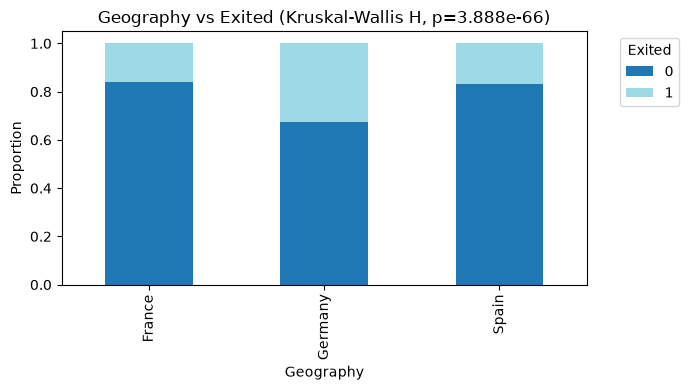

Gender: Mann-Whitney U statistic=13463530.0000, p=1.73e-26 → Significatif


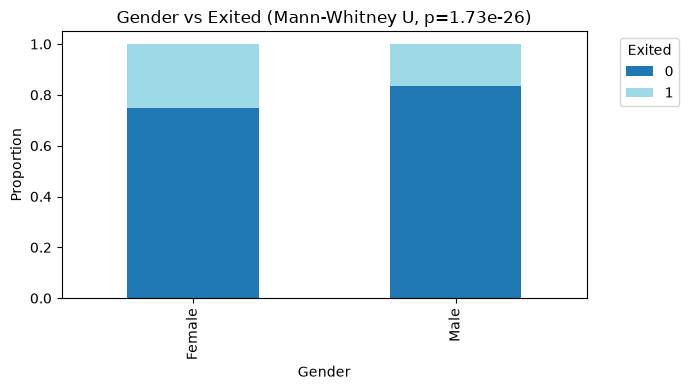

HasCrCard: Mann-Whitney U statistic=10454005.0000, p=0.4754 → Pas significatif


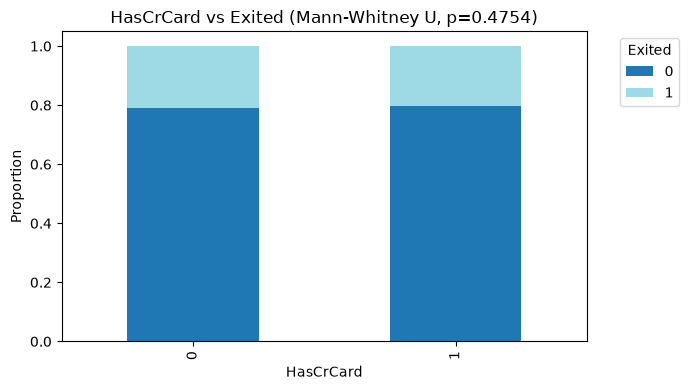

IsActiveMember: Mann-Whitney U statistic=14059893.0000, p=6.028e-55 → Significatif


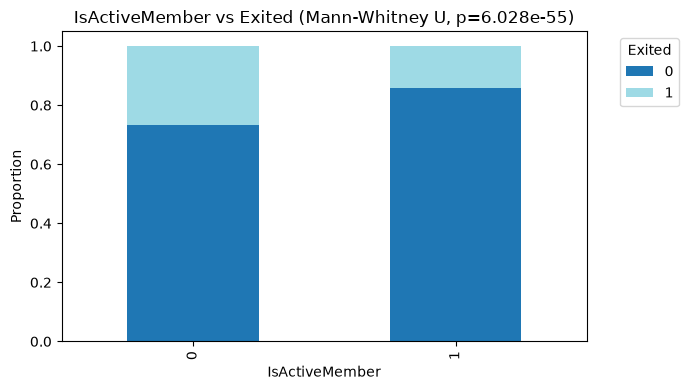

In [43]:
from scipy.stats import kruskal

target = 'Exited'
alpha = 0.05

for col in categorical_columns:
    groups = np.sort(df[col].dropna().unique())
    samples = [df[df[col] == g][target].dropna() for g in groups]

    if len(samples) == 2:
        stat, p = mannwhitneyu(samples[0], samples[1], alternative='two-sided')
        test_name = 'Mann-Whitney U'
    elif len(samples) >= 3:
        stat, p = kruskal(*samples)
        test_name = 'Kruskal-Wallis H'
    else:
        continue

    signif = 'Significatif' if p < alpha else 'Pas significatif'
    print(f"{col}: {test_name} statistic={stat:.4f}, p={p:.4g} → {signif}")

    prop_ct = pd.crosstab(df[col], df[target], normalize='index')
    prop_ct.plot(kind='bar', stacked=True, figsize=(7, 4), colormap='tab20')
    plt.title(f'{col} vs {target} ({test_name}, p={p:.4g})')
    plt.ylabel('Proportion')
    plt.xlabel(col)
    plt.legend(title=target, bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

### Informations Complementaires


=== Croisement Geography vs variables numériques ===

Geography vs CreditScore : Kruskal-Wallis H stat=0.5265, p=0.7685 → Pas significatif
           count    mean  median    std
Geography                              
France      5014  649.67   653.0  97.02
Germany     2509  651.45   651.0  98.17
Spain       2477  651.33   651.0  94.37


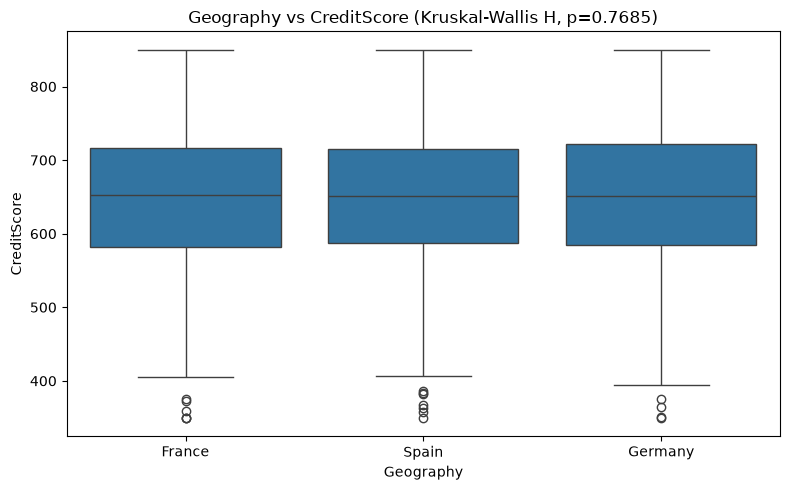


Geography vs Age : Kruskal-Wallis H stat=35.8544, p=1.638e-08 → Significatif
           count   mean  median    std
Geography                             
France      5014  38.51    37.0  10.47
Germany     2509  39.77    38.0  10.52
Spain       2477  38.89    37.0  10.45


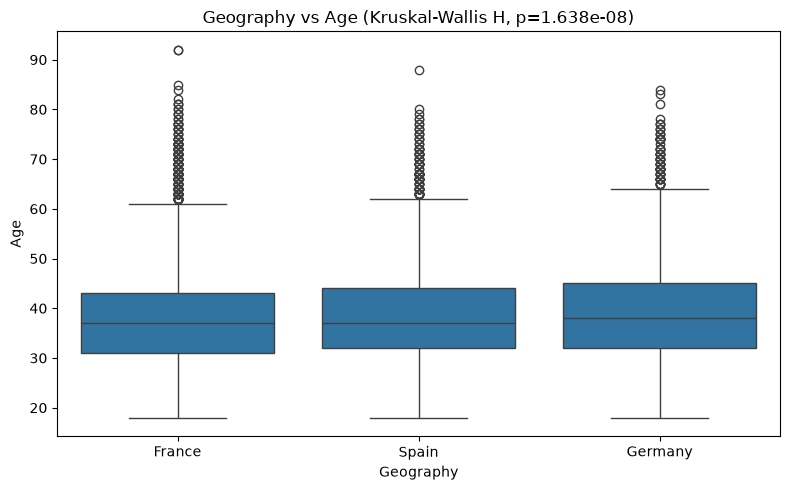


Geography vs Tenure : Kruskal-Wallis H stat=0.1713, p=0.9179 → Pas significatif
           count  mean  median   std
Geography                           
France      5014  5.00     5.0  2.89
Germany     2509  5.01     5.0  2.94
Spain       2477  5.03     5.0  2.86


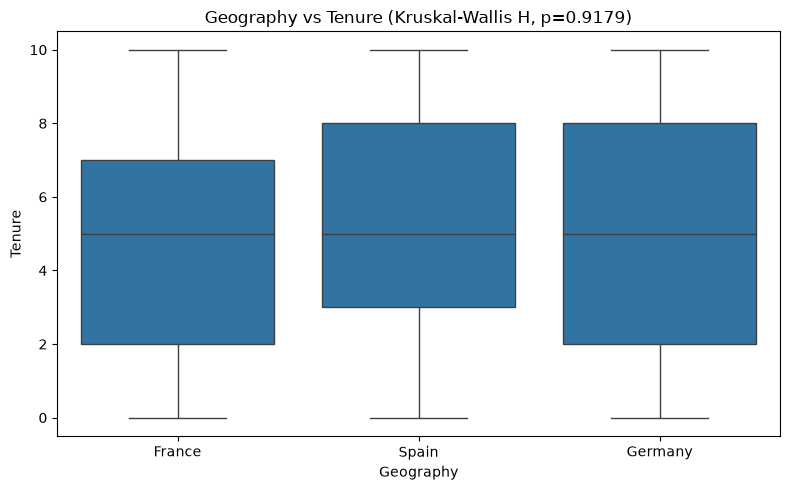


Geography vs Balance : Kruskal-Wallis H stat=1381.9344, p=8.256e-301 → Significatif
           count       mean     median       std
Geography                                       
France      5014   62092.64   62153.50  64133.57
Germany     2509  119730.12  119703.10  27022.01
Spain       2477   61818.15   61710.44  64235.56


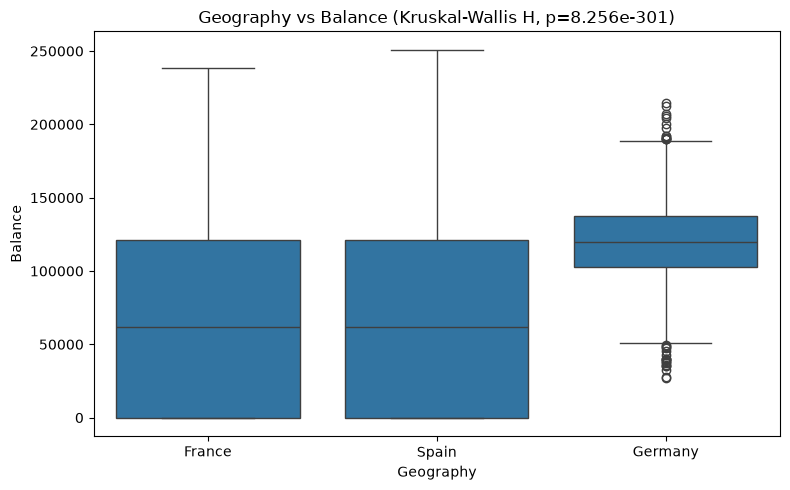


Geography vs NumOfProducts : Kruskal-Wallis H stat=6.2150, p=0.04471 → Significatif
           count  mean  median   std
Geography                           
France      5014  1.53     1.0  0.57
Germany     2509  1.52     1.0  0.62
Spain       2477  1.54     2.0  0.56


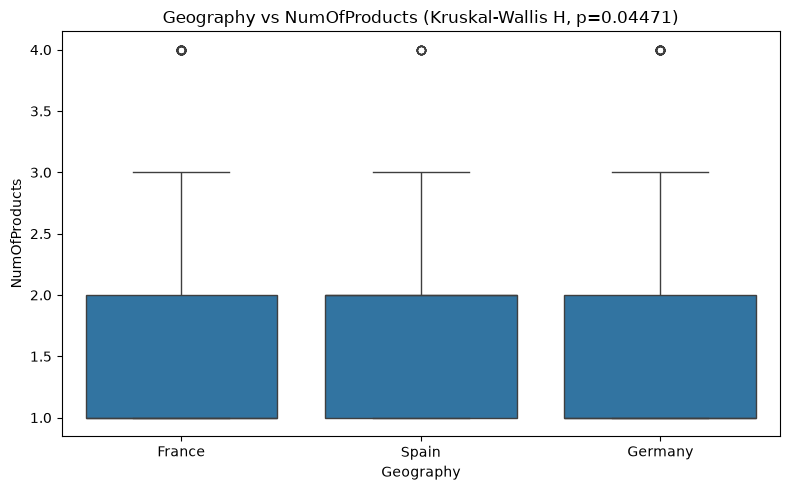


Geography vs EstimatedSalary : Kruskal-Wallis H stat=1.1278, p=0.569 → Pas significatif
           count       mean     median       std
Geography                                       
France      5014   99899.18   99132.31  57336.29
Germany     2509  101113.44  102397.22  58263.01
Spain       2477   99440.57   99984.86  57103.68


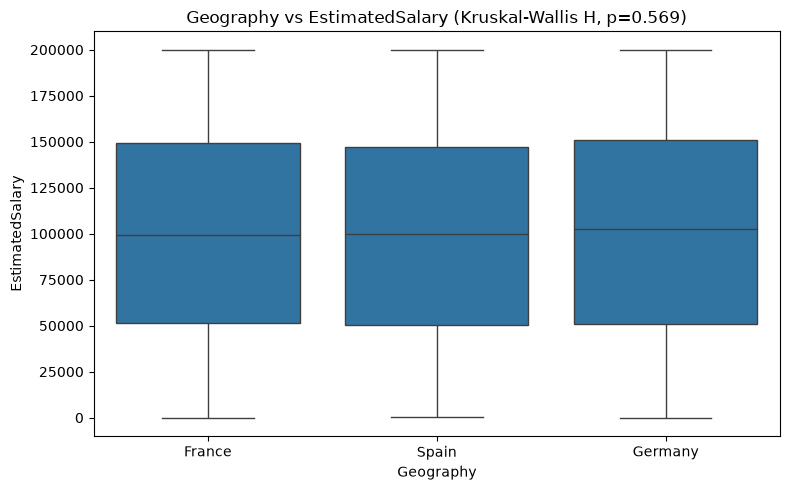


=== Croisement Gender vs variables numériques ===

Gender vs CreditScore : Mann-Whitney U stat=12438859.5000, p=0.7633 → Pas significatif
        count    mean  median    std
Gender                              
Female   4543  650.83   652.0  96.79
Male     5457  650.28   651.0  96.55


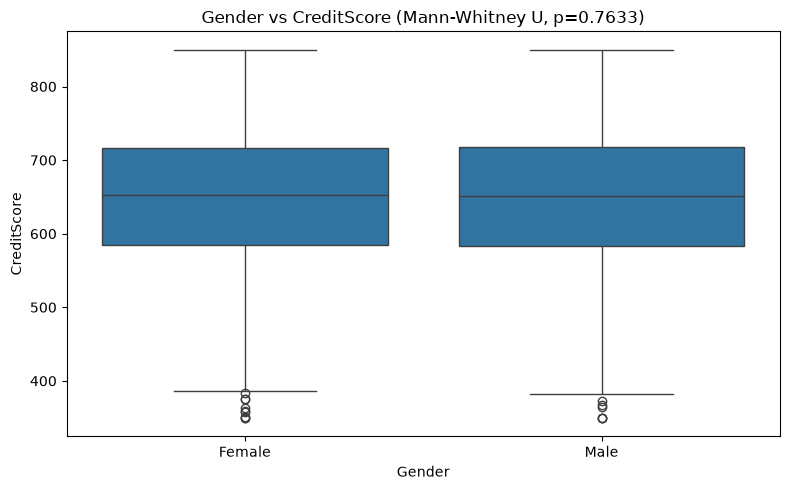


Gender vs Age : Mann-Whitney U stat=12823429.5000, p=0.002898 → Significatif
        count   mean  median    std
Gender                             
Female   4543  39.24    38.0  10.59
Male     5457  38.66    37.0  10.40


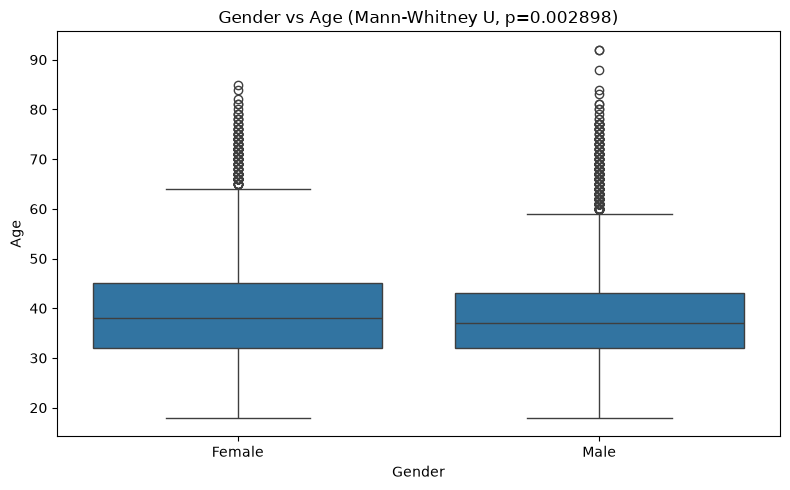


Gender vs Tenure : Mann-Whitney U stat=12179629.5000, p=0.1312 → Pas significatif
        count  mean  median   std
Gender                           
Female   4543  4.97     5.0  2.91
Male     5457  5.05     5.0  2.88


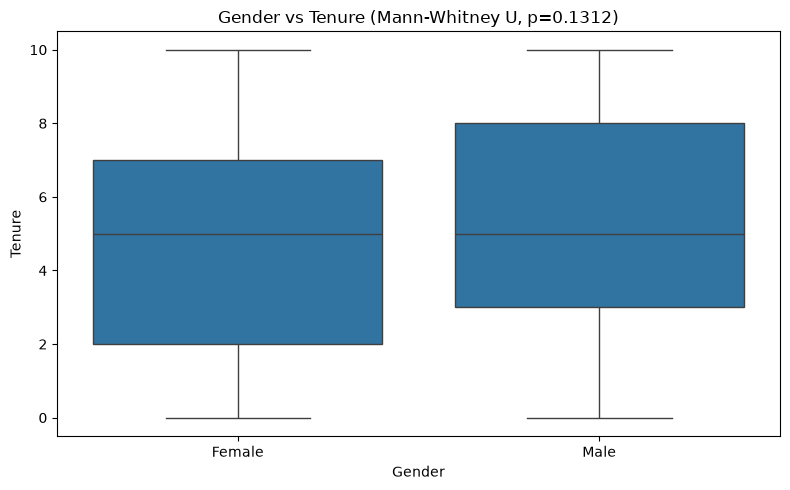


Gender vs Balance : Mann-Whitney U stat=12206120.5000, p=0.1769 → Pas significatif
        count      mean    median       std
Gender                                     
Female   4543  75659.37  96147.55  62102.47
Male     5457  77173.97  98064.97  62639.25


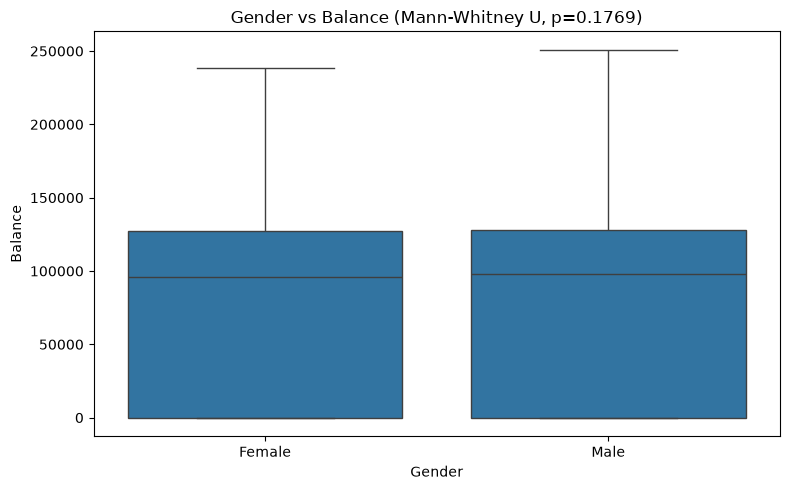


Gender vs NumOfProducts : Mann-Whitney U stat=12557850.5000, p=0.1988 → Pas significatif
        count  mean  median   std
Gender                           
Female   4543  1.54     1.0  0.60
Male     5457  1.52     1.0  0.56


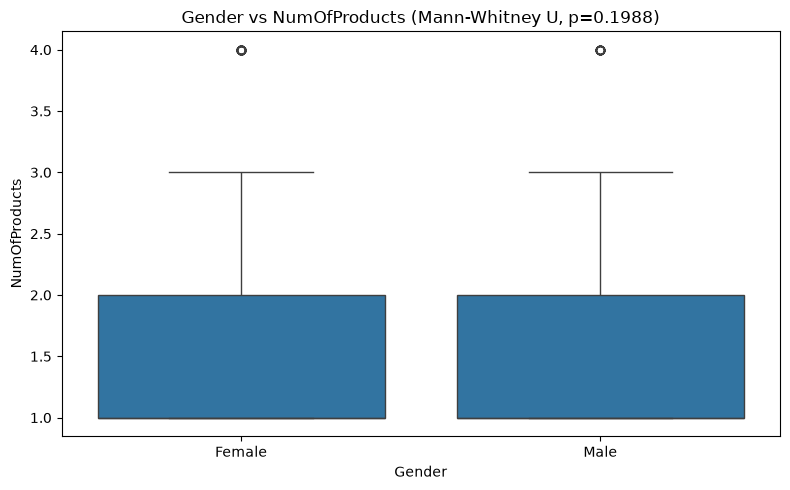


Gender vs EstimatedSalary : Mann-Whitney U stat=12514422.0000, p=0.4083 → Pas significatif
        count       mean     median       std
Gender                                       
Female   4543  100601.54  101905.34  57371.03
Male     5457   99664.58   98060.51  57628.13


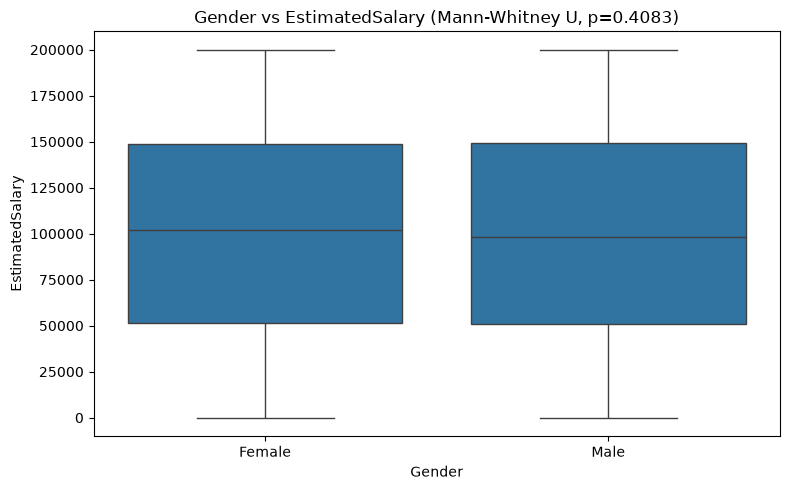


=== Croisement HasCrCard vs variables numériques ===

HasCrCard vs CreditScore : Mann-Whitney U stat=10438512.5000, p=0.7038 → Pas significatif
           count    mean  median    std
HasCrCard                              
0           2945  651.35   654.0  96.64
1           7055  650.19   651.0  96.66


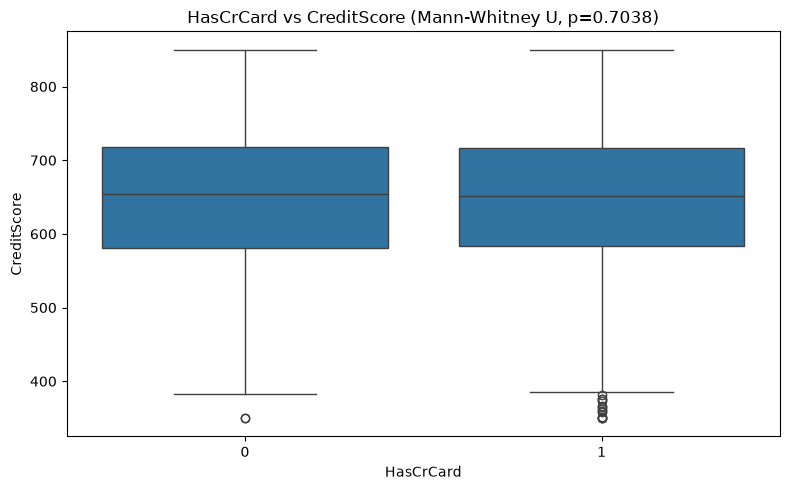


HasCrCard vs Age : Mann-Whitney U stat=10589404.5000, p=0.1266 → Pas significatif
           count   mean  median    std
HasCrCard                             
0           2945  39.11    38.0  10.53
1           7055  38.84    37.0  10.47


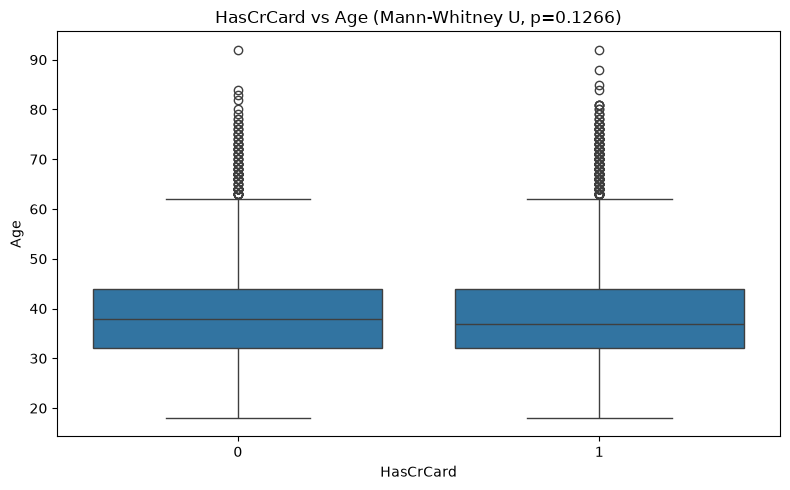


HasCrCard vs Tenure : Mann-Whitney U stat=10095745.5000, p=0.0254 → Significatif
           count  mean  median   std
HasCrCard                           
0           2945  4.91     5.0  2.93
1           7055  5.05     5.0  2.88


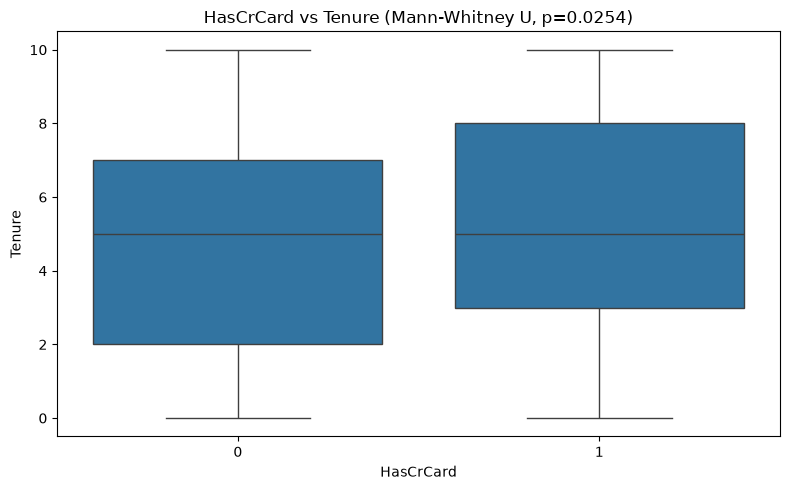


HasCrCard vs Balance : Mann-Whitney U stat=10514795.5000, p=0.3254 → Pas significatif
           count      mean    median       std
HasCrCard                                     
0           2945  77920.79  97990.49  61951.76
1           7055  75886.91  96877.21  62577.13


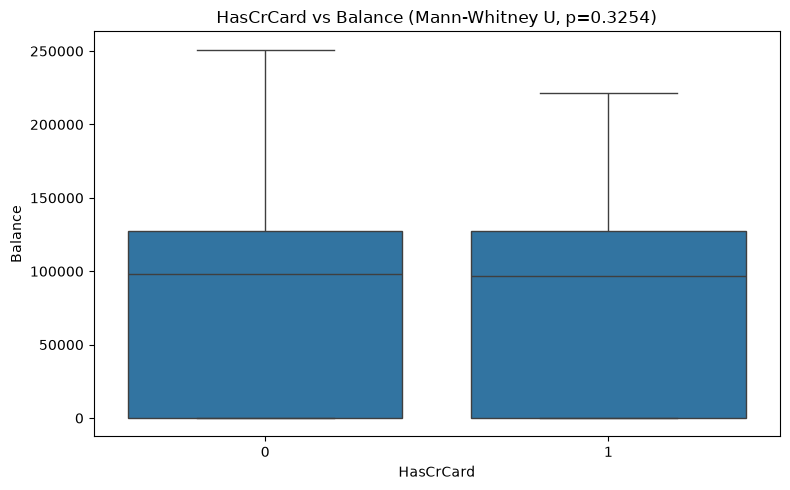


HasCrCard vs NumOfProducts : Mann-Whitney U stat=10343877.5000, p=0.6996 → Pas significatif
           count  mean  median   std
HasCrCard                           
0           2945  1.53     1.0  0.58
1           7055  1.53     1.0  0.58


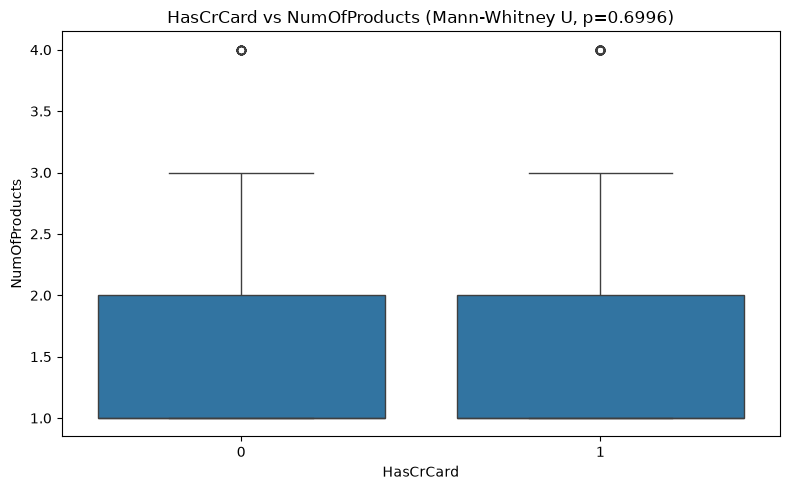


HasCrCard vs EstimatedSalary : Mann-Whitney U stat=10520609.0000, p=0.3154 → Pas significatif
           count       mean     median       std
HasCrCard                                       
0           2945  100974.40  101617.43  57761.34
1           7055   99721.16   99398.36  57405.53


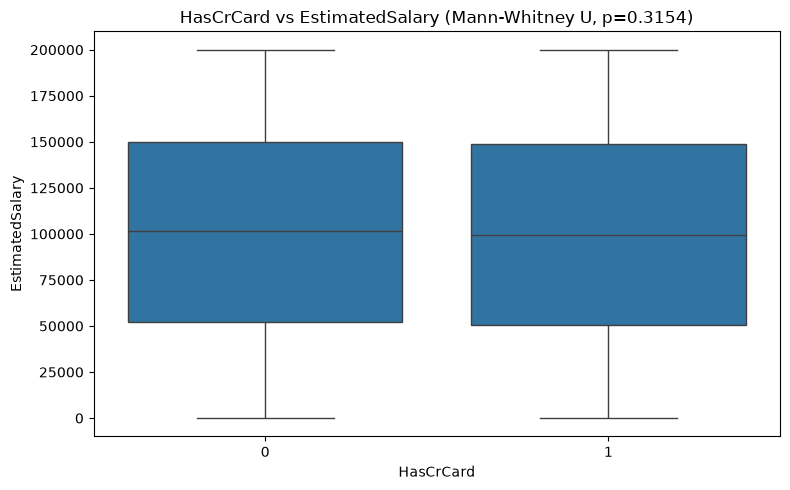


=== Croisement IsActiveMember vs variables numériques ===

IsActiveMember vs CreditScore : Mann-Whitney U stat=12138566.5000, p=0.01526 → Significatif
                count    mean  median    std
IsActiveMember                              
0                4849  647.97   650.0  97.73
1                5151  652.93   655.0  95.58


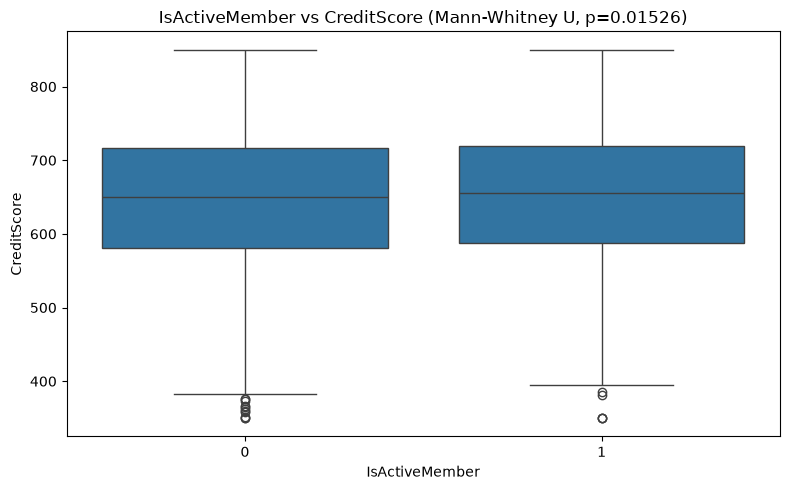


IsActiveMember vs Age : Mann-Whitney U stat=11914173.0000, p=6.785e-05 → Significatif
                count   mean  median    std
IsActiveMember                             
0                4849  38.00    37.0   8.94
1                5151  39.79    37.0  11.69


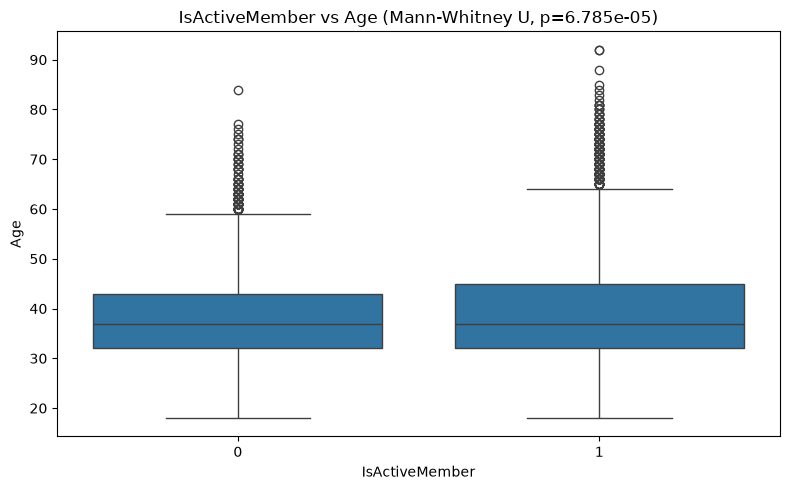


IsActiveMember vs Tenure : Mann-Whitney U stat=12900304.5000, p=0.004141 → Significatif
                count  mean  median   std
IsActiveMember                           
0                4849  5.10     5.0  2.88
1                5151  4.93     5.0  2.90


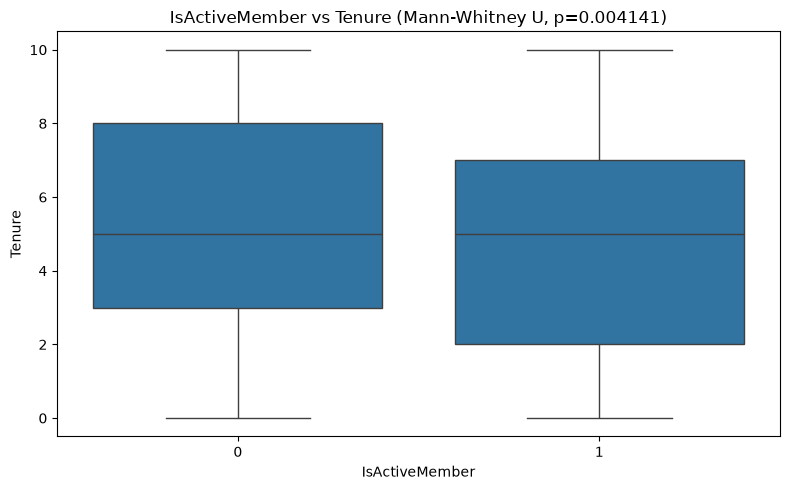


IsActiveMember vs Balance : Mann-Whitney U stat=12650490.0000, p=0.2503 → Pas significatif
                count      mean    median       std
IsActiveMember                                     
0                4849  77134.38  98263.46  62545.20
1                5151  75875.42  96166.88  62257.86


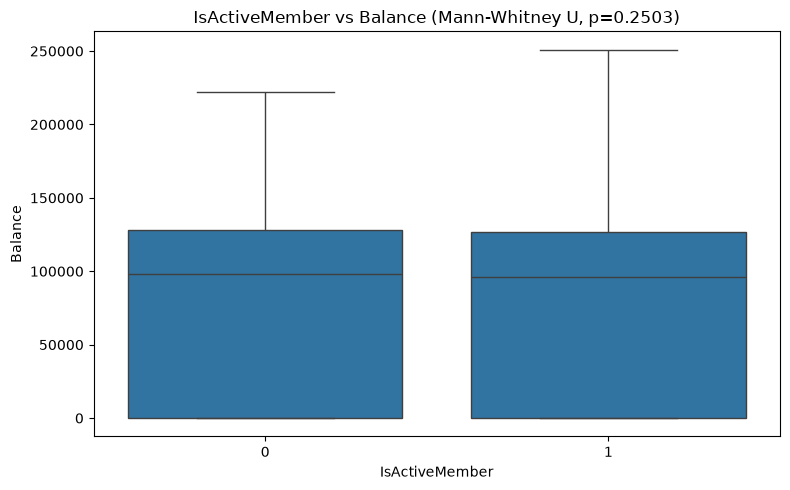


IsActiveMember vs NumOfProducts : Mann-Whitney U stat=12282098.5000, p=0.1033 → Pas significatif
                count  mean  median   std
IsActiveMember                           
0                4849  1.52     1.0  0.59
1                5151  1.54     2.0  0.57


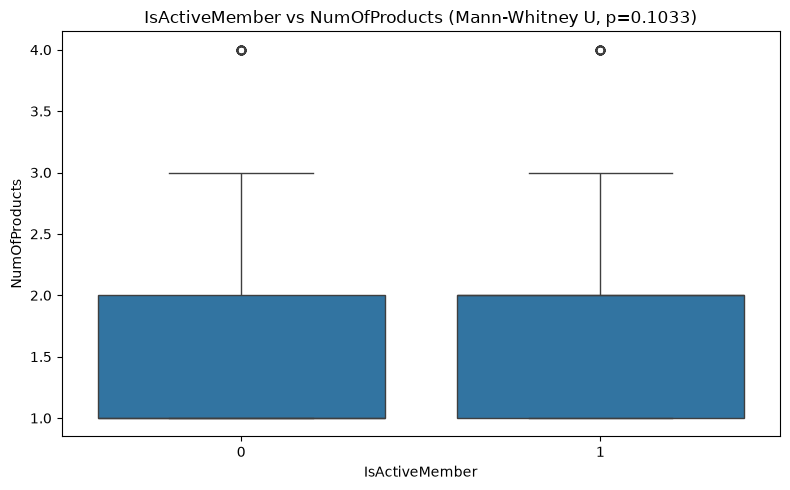


IsActiveMember vs EstimatedSalary : Mann-Whitney U stat=12654065.5000, p=0.2514 → Pas significatif
                count       mean     median       std
IsActiveMember                                       
0                4849  100767.20  100686.11  57561.19
1                5151   99452.97   99505.75  57461.03


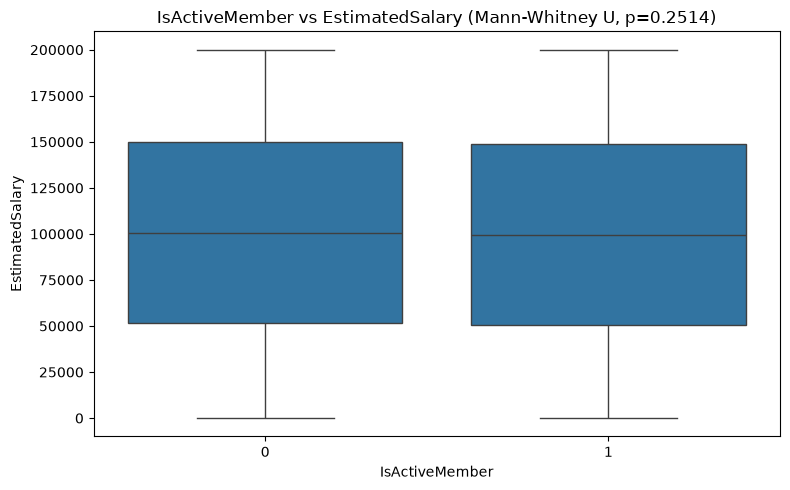

In [44]:
for cat in categorical_columns:
    print(f"\n=== Croisement {cat} vs variables numériques ===")
    for num in numeric_columns.columns:
        groups = np.sort(df[cat].dropna().unique())
        samples = [df[df[cat] == g][num].dropna() for g in groups]

        if len(samples) < 2:
            continue

        if len(samples) == 2:
            stat, p = mannwhitneyu(samples[0], samples[1], alternative='two-sided')
            test_name = 'Mann-Whitney U'
        else:
            stat, p = kruskal(*samples)
            test_name = 'Kruskal-Wallis H'

        signif = 'Significatif' if p < alpha else 'Pas significatif'
        print(f"\n{cat} vs {num} : {test_name} stat={stat:.4f}, p={p:.4g} → {signif}")
        print(df.groupby(cat)[num].agg(['count', 'mean', 'median', 'std']).round(2))

        plt.figure(figsize=(8, 5))
        sns.boxplot(data=df, x=cat, y=num)
        plt.title(f'{cat} vs {num} ({test_name}, p={p:.4g})')
        plt.xlabel(cat)
        plt.ylabel(num)
        plt.tight_layout()
        plt.show()